# Trotter error

It is interesting for us to achieve the longer time of evolution with the layer budget we have available when using real quantum devices. Recall that in principle, more Trotter layers yield more precision in the dynamical simulation, however longer circuits result in accumulation of circuit-level errors and thus worse results. We can find the optimal number of Trotter layers given a certain error per layer that can be measured. We were using EPLG as a metric for hardware noise before, but found that this quantity overestimated the effect of errors, because it did not take into account the effect of our noise mitigation strategies. We found that it was possible to measure the error per layer $p$ just by running two Trotter layers of our time evolution circuit in compute-uncompute fashion, with all the noise mitigation techniques activated, and then to extrapolate the hardware error in a circuit of $N$ trotter layers as

$$\varepsilon_H(N) = 1 - (1 - p)^N$$

We can then compare this expression with the upper bound on the error of the second order Trotter expansion from [PRX 11, 011020 (2021)](https://doi.org/10.1103/PhysRevX.11.011020)

$$U_N(t) = \prod_k^N e^{-i H_M t / 2 N} e^{-i H_I t / N} e^{-i H_M t / 2 N}$$

$$\|U_N - e^{- i H t/N} \| = \frac{t^3}{12 N^3} \| [H_I, [H_I, H_M]] \| + \frac{t^3}{24 N^3} \| [H_M, [H_M, H_I]] \|$$

In this notebook, we use ```SymPy``` to comute the norm of the commutator in the previous equation in the HeavyHex lattice. This computation is analitically doable. We have done it already in the 1D case and it can be extended to the 2D Heavy-Hex lattice without much trouble. However, this computation is sensitive to the boundary of the lattice. Instead of having to redo this computation many times for different layouts, we will use the power of symbolic computation no to do this tedious exercise a single time.

In [2]:
from sympy.physics.paulialgebra import Pauli, evaluate_pauli_product
from sympy.core.singleton import Singleton
from sympy import I, Mul, Add
from sympy.core.numbers import One
from copy import copy
import numpy as np

class PauliTensor:
    def __init__(self, factors, coefficient=1):
        coefficients = []
        paulis = []
        for factor in factors:
            if not isinstance(factor, (Pauli, Mul, One, Singleton)):
                raise ValueError("factors must be Sympy Pauli objects")
            if isinstance(factor, (One, Singleton)):
                paulis.append(One)
            else:
                prodels = factor.as_coeff_Mul(rational=True)
                coefficients.append(prodels[0])
                paulis.append(prodels[1])
        self.coefficient = np.prod(coefficients)*coefficient
        if self.coefficient.is_integer:
            self.coefficient = int(self.coefficient)
        self.paulis = paulis
        self.nqubits = len(factors)

    @classmethod
    def from_string(cls, string):
        string_to_op_dict = {"I": One, "X": Pauli(1), "Y":Pauli(2), "Z":Pauli(3)}
        chars = list(string)
        paulis = []
        coeff = 1
        for char in chars:
            if char not in string_to_op_dict.keys():
                try:
                    if char == "i":
                        this_coeff = I
                    elif char == "--":
                        this_coeff = -1
                    else:
                        this_coeff = int(char)
                    coeff *= this_coeff
                except ValueError:
                    raise ValueError("Pauli string must only contain ints, i, -, or the following characters [\"I\", \"X\", \"Y\", \"Z\"]")
            else:
                paulis.append(string_to_op_dict[char])
        return cls(paulis, coeff)
    
    def __mul__(self, other):
        if not isinstance(other, (int, float, complex, PauliTensor)):
            raise TypeError(f"can't multiply PauliTensor by element of type \'{type(other)}\'")
        elif isinstance(other, (int, float, complex)):
            final_coefficient = self.coefficient * other
            new_prod = copy(self)
            new_prod.coefficient = final_coefficient
            return new_prod
        elif isinstance(other, PauliTensor):
            if len(self) != len(other):
                raise TypeError("can't multiply PauliTensor with different dimension")
            new_paulis = []
            for self_pauli, other_pauli in zip(self.paulis, other.paulis):
                if self_pauli is One:
                    this_new_pauli = other_pauli
                elif other_pauli is One:
                    this_new_pauli = self_pauli
                else:
                    this_new_pauli = evaluate_pauli_product(self_pauli*other_pauli)
                new_paulis.append(this_new_pauli)
            # new_paulis = [evaluate_pauli_product(self_pauli*other_pauli) for self_pauli, other_pauli in zip(self.paulis, other.paulis)]
            imaginary_units = 1
            extra_coefficients = 1
            for i, pauli in enumerate(new_paulis):
                if isinstance(pauli, Mul):
                    coeff_product = pauli.as_two_terms()
                    extra_coefficients *= coeff_product[0]
                    try:
                        new_paulis[i] = coeff_product[1].as_two_terms()[1]
                        imaginary_units *= coeff_product[1].as_two_terms()[0]
                    except AttributeError:
                        new_paulis[i] = coeff_product[1]
            new_coefficient = self.coefficient * other.coefficient * extra_coefficients * imaginary_units
            if new_coefficient == 0:
                return PauliTensor([], new_coefficient)
            else:
                return PauliTensor(new_paulis, new_coefficient)
        
    def __rmul__(self, other):
        if not isinstance(other, (int, float, complex, PauliTensor)):
            raise TypeError(f"can't multiply PauliTensor by element of type \'{type(other)}\'")
        elif isinstance(other, (int, float, complex)):
            return PauliTensor.__mul__(self, other)
        
    def __add__(self, other):
        if isinstance(other, (int, float, complex)):
            return PauliTensorSum(self, PauliTensor([One]*len(self), coefficient=other))
        elif isinstance(other, PauliTensor):
            return PauliTensorSum(self, other)
        else:
            raise TypeError(f"can't sum PauliTensor and element of type \'{type(other)}\'")
        
    def __radd__(self, other):
        if isinstance(other, (int, float, complex)):
            return PauliTensorSum(self, PauliTensor([One]*len(self), coefficient=other))
        else:
            raise TypeError(f"can't sum PauliTensor and element of type \'{type(other)}\'")

    def __sub__(self, other):
        if isinstance(other, (int, float, complex)):
            return PauliTensorSum(self, PauliTensor([One]*len(self), coefficient=-other))
        elif isinstance(other, PauliTensor):
            negother = PauliTensor(other.paulis, -other.coefficient)
            return PauliTensorSum(self, negother)
        else:
            raise TypeError(f"can't substract PauliTensor and element of type \'{type(other)}\'")
        
    def __rsub__(self, other):
        if isinstance(other, (int, float, complex)):
            return PauliTensorSum(PauliTensor([One]*len(self), coefficient=other), PauliTensor(self.paulis, -self.coefficient))
        else:
            raise TypeError(f"can't sum PauliTensor and element of type \'{type(other)}\'")

    def __len__(self):
        return self.nqubits

    def __repr__(self):
        pauli_str = {One:"I", Pauli(1):"X", Pauli(2):"Y", Pauli(3):"Z"}
        if isinstance(self.coefficient, Mul):
            if self.coefficient.as_two_terms()[1] == I:
                if (c := self.coefficient.as_two_terms()[0]) == -1:
                    coeff_str = "-i*"
                else:
                    coeff_str = f"{c}i*"
            else:
                coeff_str = f"{self.coefficient}*"
        elif isinstance(self.coefficient, Add):
            coeff_str = f"({self.coefficient})*"
        else:
            if self.coefficient == -1:
                coeff_str = "-"
            elif self.coefficient == 1:
                coeff_str = ""
            else:
                coeff_str = str(self.coefficient)
        coeff_str = coeff_str.rstrip("0")
        if self.coefficient == 0:
            coeff_str = "0"
        if self.is_identity():
            pauli_strs = [""]
        else:
            pauli_strs = [pauli_str[pauli] for pauli in self.paulis]
        return f"".join([coeff_str] + pauli_strs)
    
    def __lt__(self, other):
        if not isinstance(other, PauliTensor):
            raise TypeError(f"can't compare PauliTensor with element of type \'{type(other)}\'")
        if self.paulis == other.paulis:
            return self.coefficient < other.coefficient
        else:
            return False 

    def __leq__(self, other):
        if not isinstance(other, PauliTensor):
            raise TypeError(f"can't compare PauliTensor with element of type \'{type(other)}\'")
        if self.paulis == other.paulis:
            return self.coefficient <= other.coefficient
        else:
            return False
        
    def __gt__(self, other):
        if not isinstance(other, PauliTensor):
            raise TypeError(f"can't compare PauliTensor with element of type \'{type(other)}\'")
        if self.paulis == other.paulis:
            return self.coefficient > other.coefficient
        else:
            return False
        
    def __geq__(self, other):
        if not isinstance(other, PauliTensor):
            raise TypeError(f"can't compare PauliTensor with element of type \'{type(other)}\'")
        if self.paulis == other.paulis:
            return self.coefficient > other.coefficient
        else:
            return False

    def __eq__(self, other):
        if not isinstance(other, PauliTensor):
            raise TypeError(f"can't compare PauliTensor with element of type \'{type(other)}\'")
        return (self.coefficient == other.coefficient == 0) or (self.paulis == other.paulis) and (self.coefficient == other.coefficient)
    
    def has_same_paulis(self, other):
        if not isinstance(other, PauliTensor):
            raise TypeError(f"can't compare PauliTensor with element of type \'{type(other)}\'")
        return self.paulis == other.paulis
    
    def is_identity(self):
        return all([pauli == One for pauli in self.paulis])
    
class PauliTensorSum:
    def __init__(self, *products):
        if any([not isinstance(product, PauliTensor) for product in products]):
            raise TypeError("all products must be of type PauliTensor")
        self.nqubits = None
        self.summands = []
        for product in products:
            if not isinstance(product, PauliTensor):
                raise TypeError("all products must be of type PauliTensor")
            if len(product) != 0 and self.nqubits is None:
                self.nqubits = len(product)
                self.summands = [product]
            elif len(product) != 0:
                if len(product) != self.nqubits:
                    raise ValueError("all products must have the same dimension")
                else:
                    for i, present_product in enumerate(self.summands):
                        if present_product.has_same_paulis(product):
                            sumcoeff =  present_product.coefficient + product.coefficient
                            if sumcoeff != 0:
                                self.summands[i] = PauliTensor(present_product.paulis, present_product.coefficient + product.coefficient)
                            else:
                                self.summands[i] = PauliTensor([], 0)
                            break
                    else:
                        self.summands.append(product)
        if len(self.summands) == 0:
            self.summands = [PauliTensor([], 0)]

    def __add__(self, other):
        if isinstance(other, (int, float, complex)):
            return PauliTensorSum(*self.summands, PauliTensor([One], coefficient=other))
        elif isinstance(other, PauliTensor):
            return PauliTensorSum(*self.summands, other)
        elif isinstance(other, PauliTensorSum):
            return PauliTensorSum(*self.summands, *other.summands)
        else:
            raise TypeError(f"can't sum PauliTensorSum and an element of type \'{type(other)}\'")
        
    def __radd__(self, other):
        if isinstance(other, (int, float, complex)):
            return PauliTensorSum(*self.summands, PauliTensor([One], coefficient=other))
        elif isinstance(other, PauliTensor):
            return PauliTensorSum(*self.summands, other)
        else:
            raise TypeError(f"can't sum PauliTensorSum and an element of type \'{type(other)}\'")
        
    def __sub__(self, other):
        if isinstance(other, (int, float, complex)):
            return PauliTensorSum(*self.summands, PauliTensor([One], coefficient=-other))
        elif isinstance(other, PauliTensor):
            return PauliTensorSum(*self.summands, other)
        elif isinstance(other, PauliTensorSum):
            return PauliTensorSum(*self.summands, *[PauliTensor(summand.paulis, -summand.coefficient) for summand in other.summands])
        else:
            raise TypeError(f"can't substract PauliTensorSum and element of type \'{type(other)}\'")
        
    def __rsub__(self, other):
        negself = PauliTensorSum(*[PauliTensor(summand.paulis, -summand.coefficient) for summand in self])
        if isinstance(other, (int, float, complex)):
            return PauliTensorSum(PauliTensor([One], other), *negself.summands)
        elif isinstance(other, PauliTensor):
            return PauliTensorSum(other, negself)
        elif isinstance(other, PauliTensorSum):
            return PauliTensorSum(*other.summands, *negself.summands)
        else:
            TypeError(f"can't substract PauliTensorSum and element of type \'{type(other)}\'")

    def norm_upper_bound(self):
        return np.sum([np.abs(summand.coefficient) for summand in self.summands])
    
    def __repr__(self):
        strings_to_join = [str(self.summands[0])]
        for summand in self.summands[1::]:
            summand_str = str(summand)
            if summand_str[0] == "-":
                joiner = " - "
                summand_str = summand_str[1::]
            else:
                joiner = " + "
            strings_to_join += [joiner, summand_str]
        return "".join(strings_to_join)
    
def commutator(pauli1, pauli2):
    if not (isinstance(pauli1, (Pauli, PauliTensor, PauliTensorSum)) or isinstance(pauli2, (Pauli, PauliTensor, PauliTensorSum))):
        raise TypeError("commutator aguments must be Pauli, PauliTensor or PauliTensorSum")
    if isinstance(pauli1, Pauli):
        paulisum1 = PauliTensorSum(PauliTensor(pauli1))
    elif isinstance(pauli1, PauliTensor):
        paulisum1 = PauliTensorSum(pauli1)
    else:
        paulisum1 = pauli1
    if isinstance(pauli2, Pauli):
        paulisum2 = PauliTensorSum(PauliTensor(pauli2))
    elif isinstance(pauli2, PauliTensor):
        paulisum2 = PauliTensorSum(pauli2)
    else:
        paulisum2 = pauli2

    commutator_sum = []
    for p1 in paulisum1.summands:
        for p2 in paulisum2.summands:
            commutator_sum.append(p1*p2 - p2*p1)
    
    return PauliTensorSum(*[result.summands[0] for result in commutator_sum])

def chain_interacting_terms(chain_length, lamb):
    left_interaction_qubits = np.arange(0, 2*chain_length-2, 2)
    each_interaction_qubits = np.zeros((len(left_interaction_qubits), 3))
    each_interaction_qubits[:, 0] = left_interaction_qubits
    each_interaction_qubits[:, 1] = each_interaction_qubits[:, 0] + 1
    each_interaction_qubits[:, 2] = each_interaction_qubits[:, 1] + 1
    all_qubits = np.arange(2*chain_length-1)
    tensors_to_sum = [PauliTensor([Pauli(1) if i in int_qubits else One for i in all_qubits], coefficient=-lamb) for int_qubits in each_interaction_qubits]
    return PauliTensorSum(*tensors_to_sum)

def chain_diagonal_terms(chain_length, J, h):
    nqubits = 2*chain_length - 1
    tensors_to_sum = [PauliTensor([Pauli(3) if j == i else One for j in range(nqubits)], coefficient=-J if i%2==0 else -h) for i in range(nqubits)]
    return PauliTensorSum(*tensors_to_sum)

def chain_trotter_error(t, chain_length, J, h, lamb):
    diag_terms = chain_diagonal_terms(chain_length, J, h)
    int_terms = chain_interacting_terms(chain_length, lamb)
    int_int_diag_commutator_norm = commutator(int_terms, commutator(int_terms, diag_terms)).norm_upper_bound()
    diag_diag_int_commutator_norm = commutator(diag_terms, commutator(diag_terms, int_terms)).norm_upper_bound()
    return t**3/12*int_int_diag_commutator_norm + t**3/24*diag_diag_int_commutator_norm

def chain_ntrotter_layers(t, epsilon, chain_length, J, h, lamb):
    diag_terms = chain_diagonal_terms(chain_length, J, h)
    int_terms = chain_interacting_terms(chain_length, lamb)
    int_int_diag_commutator_norm = commutator(int_terms, commutator(int_terms, diag_terms)).norm_upper_bound()
    diag_diag_int_commutator_norm = commutator(diag_terms, commutator(diag_terms, int_terms)).norm_upper_bound()
    return t/epsilon**(1/3)/12*int_int_diag_commutator_norm + t/epsilon**(1/3)/24*diag_diag_int_commutator_norm

In [3]:
L = 31

J = 1
h = 0.05
lamb = 1

chain_trotter_error(0.1, L, J, h, lamb)

0.0608458333333333

In [4]:
def chain_erradj_number_of_trotter_layers(times, eplg_absolute, chain_length, J, h, lamb, max_layers=50):
    times_matrix = np.repeat(times, max_layers).reshape(len(times), max_layers)
    layers_arr = np.arange(1, max_layers + 1)
    error_trotter = chain_trotter_error(times_matrix/layers_arr, chain_length, J, h, lamb)
    error_hardware = 1 - (1-eplg_absolute)**layers_arr
    error_total = error_trotter + error_hardware
    return np.minimum(np.argmin(error_total, axis=1) + 1, max_layers)

In [5]:
chain_erradj_number_of_trotter_layers([8], 5e-3, L, J, h, lamb, max_layers=100)

array([72])

In [6]:
chain_trotter_error(0.1, L, J, h, lamb)

0.0608458333333333

In [7]:
from sympy import symbols

Js, hs, lambs = symbols("J h λ")

chain_trotter_error(1, 2, Js, hs, lambs)#.subs([(Js, J), (hs, h), (lambs, lamb)])

0.666666666666667*Abs(J*λ**2) + 0.333333333333333*Abs(J**2*λ) + 0.333333333333333*Abs(h*λ**2) + 0.666666666666667*Abs(J*h*λ) + 0.0416666666666667*Abs(8*J**2*λ + 4*h**2*λ)

In [8]:
diag_terms = chain_diagonal_terms(L, Js, hs)
int_terms = chain_interacting_terms(L, lambs)
int_int_diag_commutator_norm = commutator(int_terms, commutator(int_terms, diag_terms)).norm_upper_bound()
diag_diag_int_commutator_norm = commutator(diag_terms, commutator(diag_terms, int_terms)).norm_upper_bound()
int_int_diag_commutator_norm

472*Abs(J*λ**2) + 120*Abs(h*λ**2)

In [9]:
diag_diag_int_commutator_norm

240*Abs(J**2*λ) + 480*Abs(J*h*λ) + 30*Abs(8*J**2*λ + 4*h**2*λ)

In [10]:
from z2chain.circs import get_erradj_number_of_trotter_layers as nlayers_trotter_analytic, error_trotter2 as chain_trotter_error_analytic

In [11]:
nlayers_trotter_analytic([8], 5e-3, L, J, h, lamb, max_layers=100)

array([65])

In [12]:
chain_trotter_error_analytic(0.1, 1, 2, J, h, lamb)

0.0013837500000000002

In [13]:
chain_ntrotter_layers(1, 1e-3, L, J, h, lamb)

608.458333333333

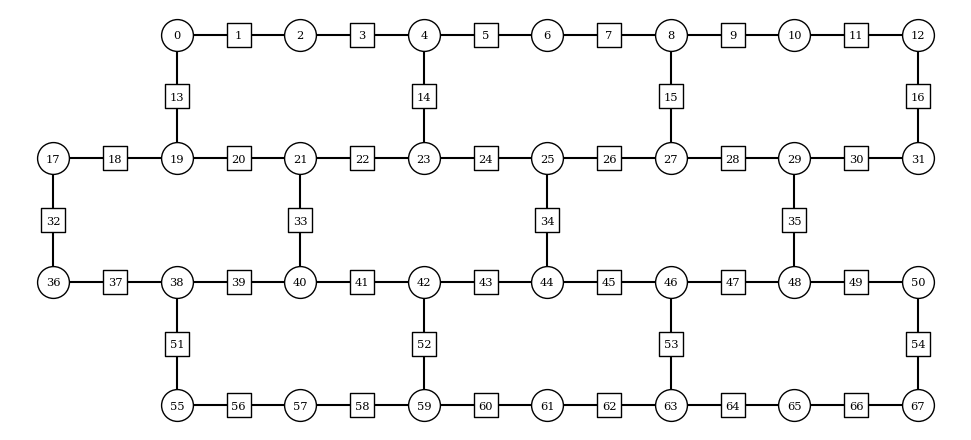

In [14]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 3
plaquette_height = 3

lattice =  HeavyHexLattice(plaquette_width, plaquette_height)
lattice.plot_lattice(number_qubits=True)

In [15]:
lattice.node_coords

[(0, 1),
 (0, 2),
 (0, 3),
 (0, 4),
 (0, 5),
 (0, 6),
 (0, 7),
 (1, 0),
 (1, 1),
 (1, 2),
 (1, 3),
 (1, 4),
 (1, 5),
 (1, 6),
 (1, 7),
 (2, 0),
 (2, 1),
 (2, 2),
 (2, 3),
 (2, 4),
 (2, 5),
 (2, 6),
 (2, 7),
 (3, 1),
 (3, 2),
 (3, 3),
 (3, 4),
 (3, 5),
 (3, 6),
 (3, 7)]

In [16]:
lattice.edge_coords

[(0, 1.5),
 (0, 2.5),
 (0, 3.5),
 (0, 4.5),
 (0, 5.5),
 (0, 6.5),
 (0.5, 1),
 (0.5, 3),
 (0.5, 5),
 (0.5, 7),
 (1, 0.5),
 (1, 1.5),
 (1, 2.5),
 (1, 3.5),
 (1, 4.5),
 (1, 5.5),
 (1, 6.5),
 (1.5, 0),
 (1.5, 2),
 (1.5, 4),
 (1.5, 6),
 (2, 0.5),
 (2, 1.5),
 (2, 2.5),
 (2, 3.5),
 (2, 4.5),
 (2, 5.5),
 (2, 6.5),
 (2.5, 1),
 (2.5, 3),
 (2.5, 5),
 (2.5, 7),
 (3, 1.5),
 (3, 2.5),
 (3, 3.5),
 (3, 4.5),
 (3, 5.5),
 (3, 6.5)]

In [17]:
[lattice.nodes_connected_to_edge(edge_coords) for edge_coords in lattice.edge_coords]

[((0, 1), (0, 2)),
 ((0, 2), (0, 3)),
 ((0, 3), (0, 4)),
 ((0, 4), (0, 5)),
 ((0, 5), (0, 6)),
 ((0, 6), (0, 7)),
 ((0, 1), (1, 1)),
 ((0, 3), (1, 3)),
 ((0, 5), (1, 5)),
 ((0, 7), (1, 7)),
 ((1, 0), (1, 1)),
 ((1, 1), (1, 2)),
 ((1, 2), (1, 3)),
 ((1, 3), (1, 4)),
 ((1, 4), (1, 5)),
 ((1, 5), (1, 6)),
 ((1, 6), (1, 7)),
 ((1, 0), (2, 0)),
 ((1, 2), (2, 2)),
 ((1, 4), (2, 4)),
 ((1, 6), (2, 6)),
 ((2, 0), (2, 1)),
 ((2, 1), (2, 2)),
 ((2, 2), (2, 3)),
 ((2, 3), (2, 4)),
 ((2, 4), (2, 5)),
 ((2, 5), (2, 6)),
 ((2, 6), (2, 7)),
 ((2, 1), (3, 1)),
 ((2, 3), (3, 3)),
 ((2, 5), (3, 5)),
 ((2, 7), (3, 7)),
 ((3, 1), (3, 2)),
 ((3, 2), (3, 3)),
 ((3, 3), (3, 4)),
 ((3, 4), (3, 5)),
 ((3, 5), (3, 6)),
 ((3, 6), (3, 7))]

In [21]:
from z2hex.geometry import HeavyHexLattice

def hex_interaction_terms(lattice: HeavyHexLattice, lamb: float):
    edge_coords = lattice.edge_coords
    connected_nodes_coords = [lattice.nodes_connected_to_edge(edge_coord) for edge_coord in edge_coords]
    edge_lowest_node_coords = [nodes_coords[0] for nodes_coords in connected_nodes_coords]
    edge_highest_node_coords = [nodes_coords[1] for nodes_coords in connected_nodes_coords]
    each_interaction_qubits = np.zeros((len(edge_coords), 3), dtype=int)
    each_interaction_qubits[:, 0] = lattice.coords_to_logical_qb(edge_lowest_node_coords)
    each_interaction_qubits[:, 1] = lattice.coords_to_logical_qb(edge_coords)
    each_interaction_qubits[:, 2] = lattice.coords_to_logical_qb(edge_highest_node_coords)
    all_qubits = np.arange(len(lattice))
    tensors_to_sum = [PauliTensor([Pauli(1) if j in this_int_qubits else One for j in all_qubits], coefficient=-lamb) for this_int_qubits in each_interaction_qubits]
    return PauliTensorSum(*tensors_to_sum)

def hex_diagonal_terms(lattice: HeavyHexLattice, J: float, h: float):
    all_qubits = np.arange(len(lattice))
    tensors_to_sum = [PauliTensor([Pauli(3) if j == this_qubit else One for j in all_qubits], coefficient=-J if this_qubit%2==0 else -h) for this_qubit in all_qubits]
    return PauliTensorSum(*tensors_to_sum)

def hex_trotter_error(t, lattice, J, h, lamb):
    diag_terms = hex_diagonal_terms(lattice, J, h)
    int_terms = hex_interaction_terms(lattice, lamb)
    int_int_diag_commutator_norm = commutator(int_terms, commutator(int_terms, diag_terms)).norm_upper_bound()
    diag_diag_int_commutator_norm = commutator(diag_terms, commutator(diag_terms, int_terms)).norm_upper_bound()
    return t**3/12*int_int_diag_commutator_norm + t**3/24*diag_diag_int_commutator_norm

def hex_trotter_layers(t, epsilon, lattice, J, h, lamb):
    diag_terms = hex_diagonal_terms(lattice, J, h)
    int_terms = hex_interaction_terms(lattice, lamb)
    int_int_diag_commutator_norm = commutator(int_terms, commutator(int_terms, diag_terms)).norm_upper_bound()
    diag_diag_int_commutator_norm = commutator(diag_terms, commutator(diag_terms, int_terms)).norm_upper_bound()
    return t/12/epsilon**(1/3)*int_int_diag_commutator_norm + t/24/epsilon**(1/3)*diag_diag_int_commutator_norm

def hex_dt(epsilon, lattice, J, h, lamb):
    diag_terms = hex_diagonal_terms(lattice, J, h)
    int_terms = hex_interaction_terms(lattice, lamb)
    int_int_diag_commutator_norm = commutator(int_terms, commutator(int_terms, diag_terms)).norm_upper_bound()
    diag_diag_int_commutator_norm = commutator(diag_terms, commutator(diag_terms, int_terms)).norm_upper_bound()
    return (epsilon/(int_int_diag_commutator_norm/12 + diag_diag_int_commutator_norm/24))**(1/3)

In [27]:
dt = hex_dt(2e-2, lattice, J, h, lamb)
dt*35

2.44330630397169

In [97]:
from sympy import symbols

Js, hs, lambs = symbols("J h λ")

In [98]:
hex_interaction_terms(lattice, lambs)

-λ*XXXIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - λ*IIXXXIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - λ*IIIIXXXIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - λ*IIIIIIXXXIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - λ*IIIIIIIIXXXIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - λ*IIIIIIIIIIXXXIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - λ*XIIIIIIIIIIIIXIIIIIXIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - λ*IIIIXIIIIIIIIIXIIIIIIIIXIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - λ*IIIIIIIIXIIIIIIXIIIIIIIIIIIXIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - λ*IIIIIIIIIIIIXIIIXIIIIIIIIIIIIIIXIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - λ*IIIIIIIIIIIIIIIIIXXXIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - λ*IIIIIIIIIIIIIIIIIIIXXXIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - λ*IIIIIIIIIIIIIIIIIIIIIXXXIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - λ*IIIIIIIIIIIIIIIIIIIIIIIXXXIIIIIIIIIIIIIIIIIIIIII

In [99]:
hex_diagonal_terms(lattice, Js, hs)

-J*ZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - h*IZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - J*IIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - h*IIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - J*IIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - h*IIIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - J*IIIIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - h*IIIIIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - J*IIIIIIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - h*IIIIIIIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - J*IIIIIIIIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - h*IIIIIIIIIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - J*IIIIIIIIIIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII - h*IIIIIIIIIIIIIZIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIIII

In [100]:
def hex_erradj_number_of_trotter_layers(times, eplg_absolute, lattice, J, h, lamb, max_layers=50):
    times_matrix = np.repeat(times, max_layers).reshape(len(times), max_layers)
    layers_arr = np.arange(1, max_layers + 1)
    error_trotter = hex_trotter_error(times_matrix/layers_arr, lattice, J, h, lamb)
    error_hardware = 1 - (1-eplg_absolute)**layers_arr
    error_total = error_trotter + error_hardware
    return np.minimum(np.argmin(error_total, axis=1) + 1, max_layers)

In [101]:
hex_erradj_number_of_trotter_layers([10], 5e-3, lattice, J, h, lamb, max_layers=100)

array([86])

In [102]:
J, h, lamb

(1, 0.05, 1)

### NOTE: The term growing largest with lattice size is $J^2 \lambda$

This implies that it is better to express time in terms of $Jt$

In [72]:
hex_trotter_layers(1, 1e-3, lattice, 2, 0.05/2, 1/2)

523.861979166667

In [73]:
hex_trotter_error(np.array([1, 1/10]), lattice, 1, 0.05/10, 1/10)

array([1.99468958333333, 0.00199468958333333], dtype=object)

In [74]:
(1/10)**(1+2)

0.0010000000000000002

In [75]:
5**3/1e-3**(1/3)

1249.9999999999998

In [76]:
from z2hex.circs import get_erradj_number_of_trotter_layers as chain_erradj_number_of_trotter_layers, trotter_error

chain_erradj_number_of_trotter_layers(np.array([10]), 1e-2, lattice, 1, 0.05, 1)

array([50])

In [77]:
import matplotlib.pyplot as plt

time = 25
max_layers = 100
eplg_absolute = 8.5e-3

J = 1
h = 0.05/25
lamb = 1/25

layers_arr = np.arange(20, max_layers + 1)
error_trotter = trotter_error(time/layers_arr, lattice, J, h, lamb)
error_hardware = 1 - (1-eplg_absolute)**layers_arr

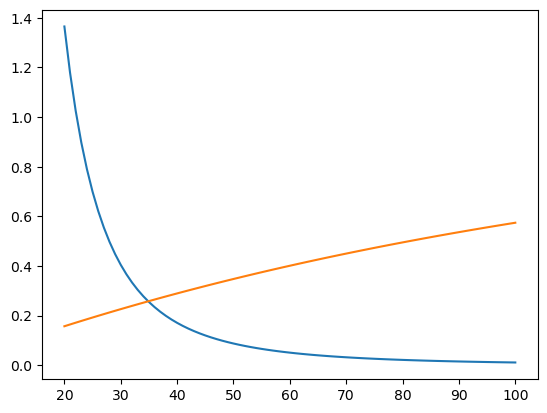

In [78]:
plt.plot(layers_arr, error_trotter)
plt.plot(layers_arr, error_hardware)